In [14]:
# Problem:
# Predicting the readmission of diabetic patients within 30-day after discharged, and how does a simple, interpretable model (Logistic Regression) compare with a more complex ensemble model (Random Forest)?

# This file will read the diabetic patients dataset and preprocess the data to create the model.

In [41]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# from src.preprocessing import load_raw

sys.path.append('..')
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures/'

In [27]:
diag_types = {'diag_1': str, 'diag_2': str, 'diag_3': str}
df = pd.read_csv('../Data/diabetic_data.csv', na_values='?', dtype=diag_types, low_memory=False)
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [42]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'unique_values': df.nunique(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'example': df.iloc[0]
})
summary.to_csv(FIG+'attribute_summary.csv')
summary

,dtype,unique_values,missing_%,example
encounter_id,int64,101766,0.00,2278392
patient_nbr,int64,71518,0.00,8222157
race,object,5,2.23,Caucasian
gender,object,3,0.00,Female
age,object,10,0.00,[0-10)
weight,object,9,96.86,NaN
admission_type_id,int64,8,0.00,6
discharge_disposition_id,int64,26,0.00,25
admission_source_id,int64,17,0.00,1
time_in_hospital,int64,14,0.00,1


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: count, dtype: float64


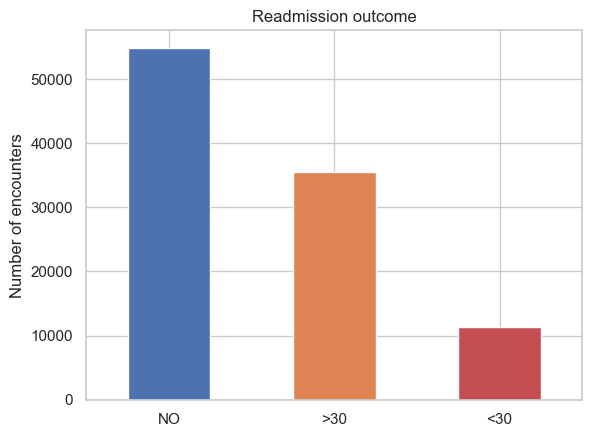

In [29]:
counts = df['readmitted'].value_counts()
print((counts/len(df)*100).round(2))

ax = counts.plot(kind='bar', color=['#4c72b0', '#dd8452', '#c44e52'])
ax.set_title('Readmission outcome')
ax.set_xlabel('')
ax.set_ylabel('Number of encounters')
plt.xticks(rotation=0)
plt.savefig(FIG +'01_target.png', dpi=150, bbox_inches='tight')
plt.show()

In [38]:
# As the classes are imbalanced, so accuracy would be misleading.
   # Only about [11.2]% of encounters ended in a readmission within 30 days, while [53.9]% were never readmitted and [34.9]% came back
   # after 30 days. Since I'm treating this as "readmitted within 30 days or not", the  class is small. Accuracy alone would be misleading here, so I'll focus on
   # PR-AUC, recall and F1 when evaluating the models.

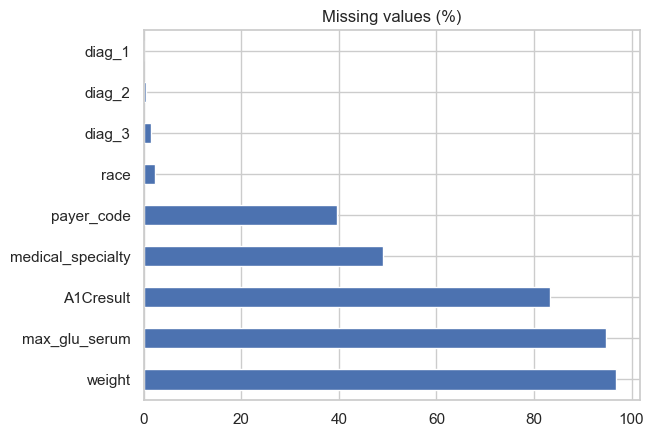

weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

In [40]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

missing.plot(kind='barh')
plt.title('Missing values (%)')
plt.savefig(FIG + '01_missing.png', dpi=150, bbox_inches='tight')
plt.show()
missing

In [44]:
# Some columns values are mostly missing 
#    `weight` is missing for about [97]% of encounters, so it can't be used. `payer_code` ([40]%) and `medical_specialty` ([49]%)
#    also have a lot of gaps. I'll drop the first two and keep `medical_specialty`, treating "missing" as its own category, because whether a specialty was recorded
#    may itself carry some information.

In [35]:
visits = df['patient_nbr'].value_counts()
print('Unique patients:', visits.size)
print('Patients with more than one encounter:', (visits > 1).sum())
print('Share of rows from repeat patients: {:1%}', format((df['patient_nbr'].map(visits) > 1).mean()))

Unique patients: 71518
Patients with more than one encounter: 16773
Share of rows from repeat patients: {:1%} 0.4620501935813533


In [ ]:
# Many patients appear more than once.
#    There are [101,766] encounters but only
#    [71,518] unique patients, and about [X]% of rows belong to patients with several
#    stays. If I split the data randomly, the same person could end up in both training
#    and testing, which would make the results look better than they really are. To avoid
#    this, I'll split the data by patient.

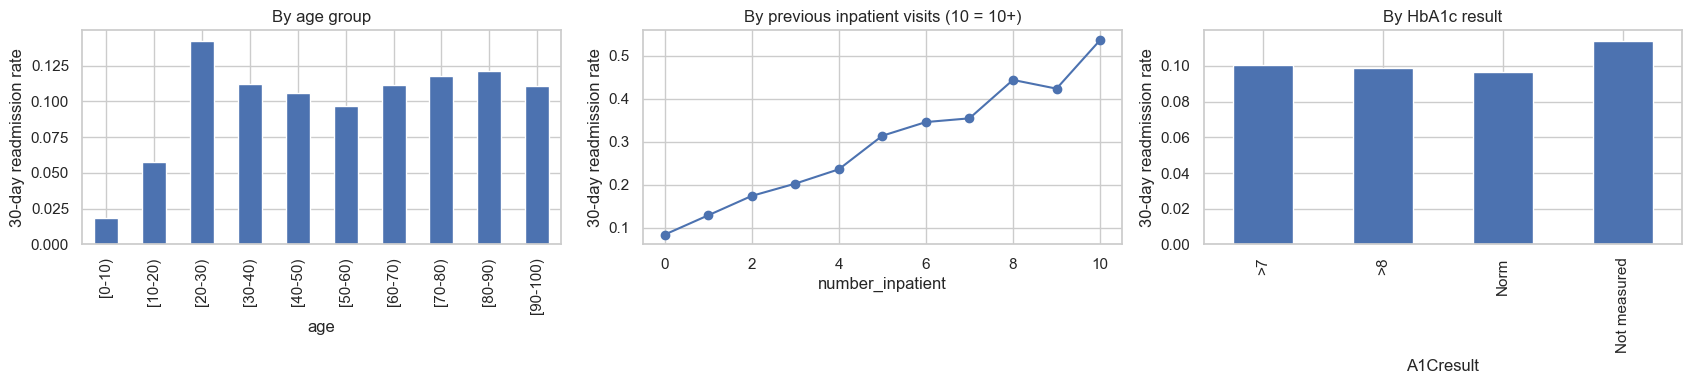

In [37]:
df['target'] = (df['readmitted'] == '<30').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df.groupby('age')['target'].mean().plot(kind='bar', ax=axes[0], title='By age group')
df.groupby(df['number_inpatient'].clip(upper=10))['target'].mean().plot(
    marker='o', ax=axes[1], title='By previous inpatient visits (10 = 10+)')
df.groupby(df['A1Cresult'].fillna('Not measured'))['target'].mean().plot(
    kind='bar', ax=axes[2], title='By HbA1c result')
for ax in axes:
    ax.set_ylabel('30-day readmission rate')
plt.tight_layout()
plt.savefig(FIG + '01_rates.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Previous hospital stays are the clearest warning sign.
#    The readmission rate rises steadily with the number of inpatient visits in the year before: from about [8]% for
#    patients with none to over [X]% for those with [5] or more. Age has a much weaker effect, and the HbA1c result shows only small differences between groups.

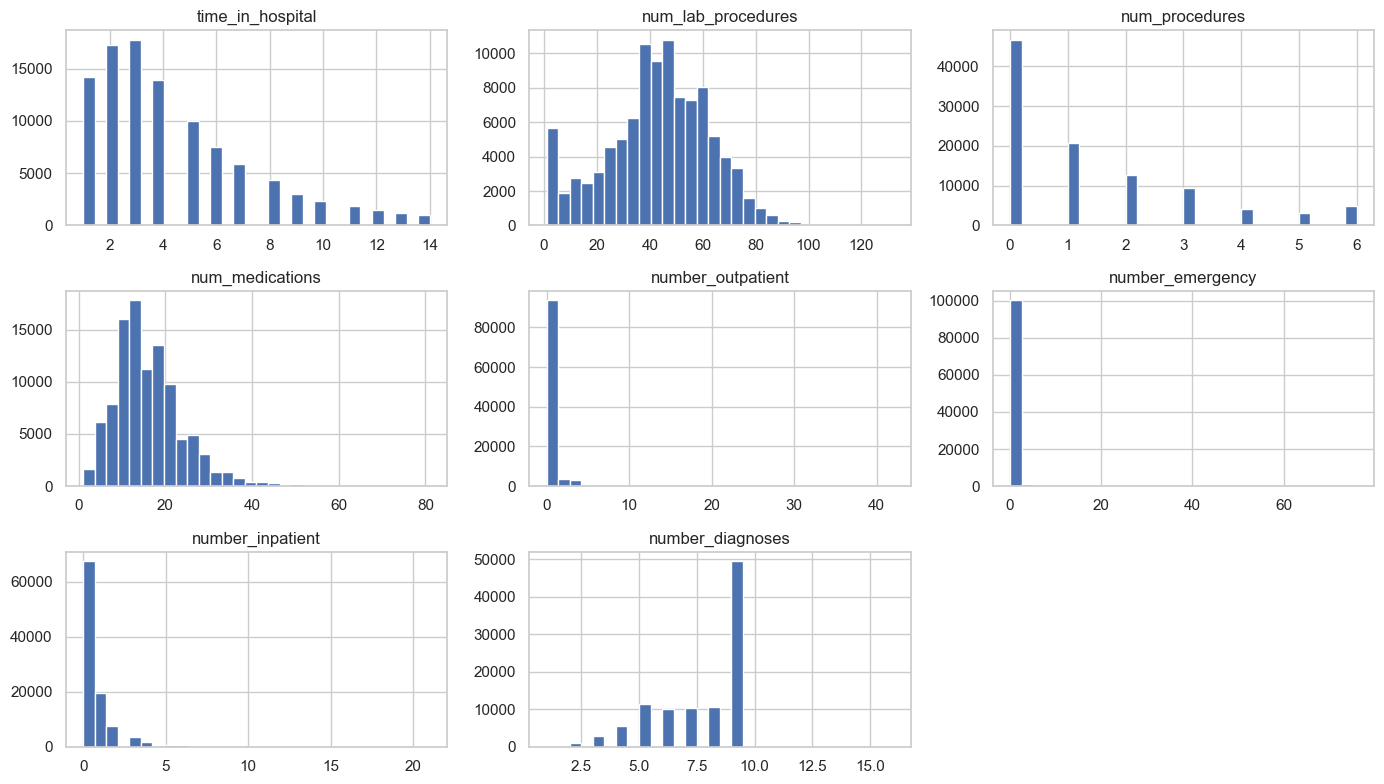

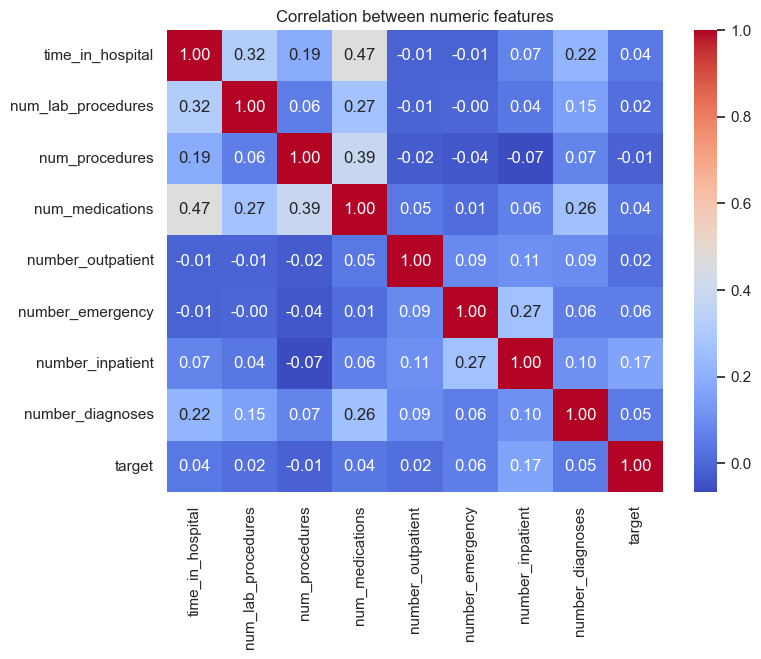

In [47]:
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
df[num_cols].hist(bins=30, figsize=(14,8))
plt.tight_layout()
plt.savefig(FIG + '01_hist.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols + ['target']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric features')
plt.savefig(FIG + '01_corr.png', dpi=150, bbox_inches='tight')
plt.show()

In [49]:
# No single numeric feature explains readmission.
#    Every correlation with the target is weak (the highest is about [0.17], for `number_inpatient`). On its own, no variable
#    is a strong predictor. Readmission seems to depend on several factors together, which is exactly why a machine learning model is needed rather than a simple rule.

# Several features are skewed and need preparing.
#    Columns such as   `number_outpatient`, `number_emergency` and `number_inpatient` are mostly zero with a long tail. 
#    The diagnosis columns contain hundreds of different ICD-9 codes, which is far too many to use directly. In the next notebook I'll group the diagnoses into
#    broader categories and scale the numeric features for Logistic Regression.